In [82]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector 
from math import pi
import numpy as np
from random import random
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

sim = AerSimulator()

In [83]:
def rename(counts):
    new_counts = {}
    trans = {"00": "00","10": "01", "01": "10","11": "11"}
    for key in counts:
        new_counts[trans[key]] = counts[key]
    return new_counts

In [87]:
def run_circuit(alpha, beta, theta0, theta1, chi, runs=10000):
    circ = QuantumCircuit(2,2)
    circ.initialize([alpha,beta],0)
    circ.ry(2*theta0,1)
    circ.cry(2*theta1 - 2*theta0,0,1)
    circ.measure(1,0)
    with circ.if_test((circ.clbits[0], 1)):
        circ.x(1)
        circ.h(0)
        circ.ry(2*chi,1)
        circ.cry(pi-4*chi,0,1)
        circ.h(0)
    circ.measure(1,1)
    display(circ.draw('mpl'))
    job = sim.run(circ, shots=runs)
    out = job.result().get_counts()
    out = rename(out)
    return out



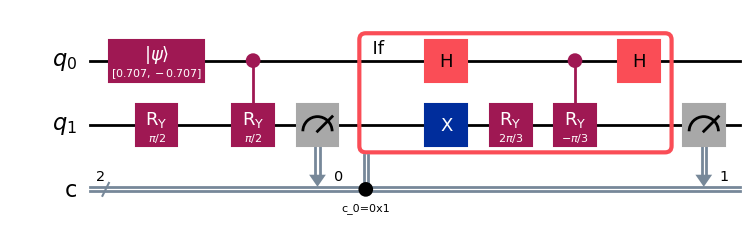

In [88]:
statistics = run_circuit(1/np.sqrt(2),-1/np.sqrt(2),pi/4,pi/2,pi/3)


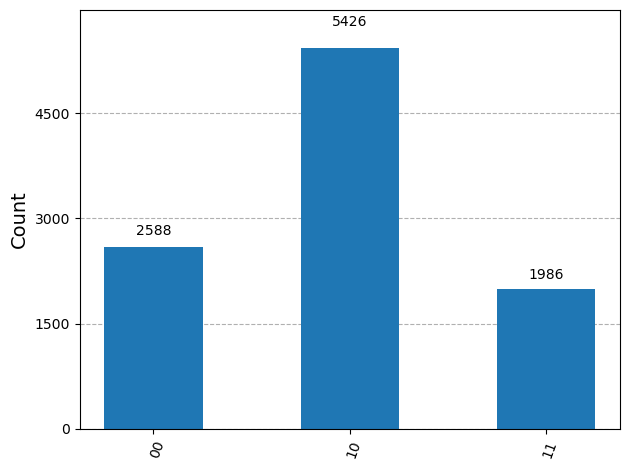

In [89]:
plot_histogram(statistics)